# 04 · Regression Models — forecasting 7-day demand

Unit 1: linear regression, polynomial curve fitting, least squares, overfitting. Unit 2: MLE/least-squares, ridge, Bayesian linear regression, robust regression.

> **Data provenance.** Sales, dates, prices, SKUs and countries are **real**
> (UCI Online Retail II, CC BY 4.0, 1,067,371 invoice lines).
> Stock levels, suppliers, lead times, MOQ, pack sizes and every cost are
> **SIMULATED** — the source dataset contains none of them. See `sim/` and
> `docs/pbl1_scope.md`.


In [1]:
import sys, os
from pathlib import Path
for _v in ("OMP_NUM_THREADS", "OPENBLAS_NUM_THREADS", "MKL_NUM_THREADS"):
    os.environ.setdefault(_v, "1")
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))

import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 60)

from xaierp.utils.config import load_config, resolve
CFG = load_config()
REPORTS = resolve(CFG["paths"]["reports"])
FIGS = resolve(CFG["paths"]["figures"])
print("project root:", ROOT)


project root: E:\downloads\ML Project


## Results

In [2]:
reg = pd.read_csv(REPORTS / 'regression_model_comparison.csv')
reg[['model', 'unit', 'test_MAE', 'test_RMSE', 'test_R2',
     'test_RMSLE', 'train_time_s']].round(4)

,model,unit,test_MAE,test_RMSE,test_R2,test_RMSLE,train_time_s
0,Ridge Regression (L2),Unit 2,136.3555,288.5329,0.5097,1.1328,0.168
1,Bayesian Linear Regression (Bayesian Ridge),Unit 2,136.3155,288.6709,0.5093,1.1303,0.916
2,Linear Regression (OLS),Unit 1 + Unit 2,134.1872,288.9576,0.5083,1.1153,0.275
3,Robust Linear Regression (Huber),Unit 2,124.0382,297.3770,0.4792,0.9385,26.772
4,Baseline: 28-day mean x horizon,Baseline (no learning),136.6951,298.1314,0.4766,0.9907,0.000
5,LightGBM (gradient-boosted trees),Advanced (beyond syllabus),142.2827,311.4316,0.4288,1.1776,2.219
6,Baseline: 7-day mean x horizon,Baseline (no learning),160.3163,352.7119,0.2674,1.0531,0.000


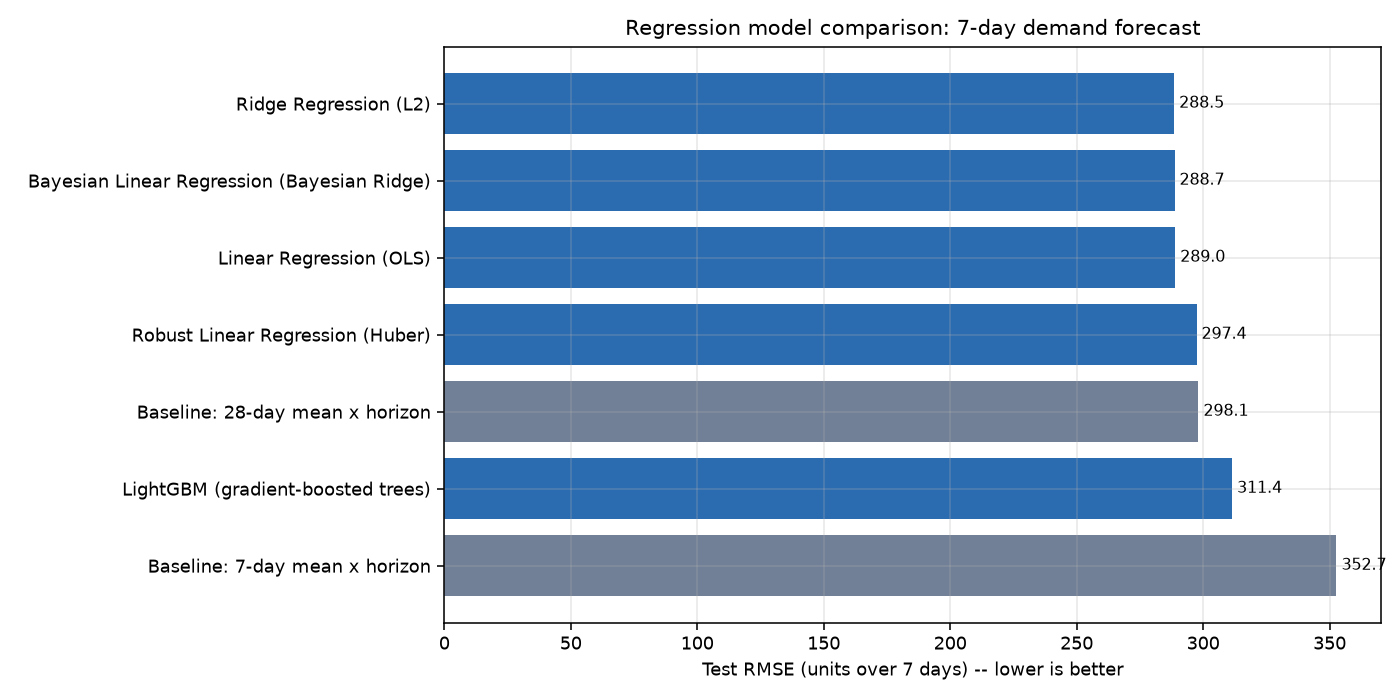

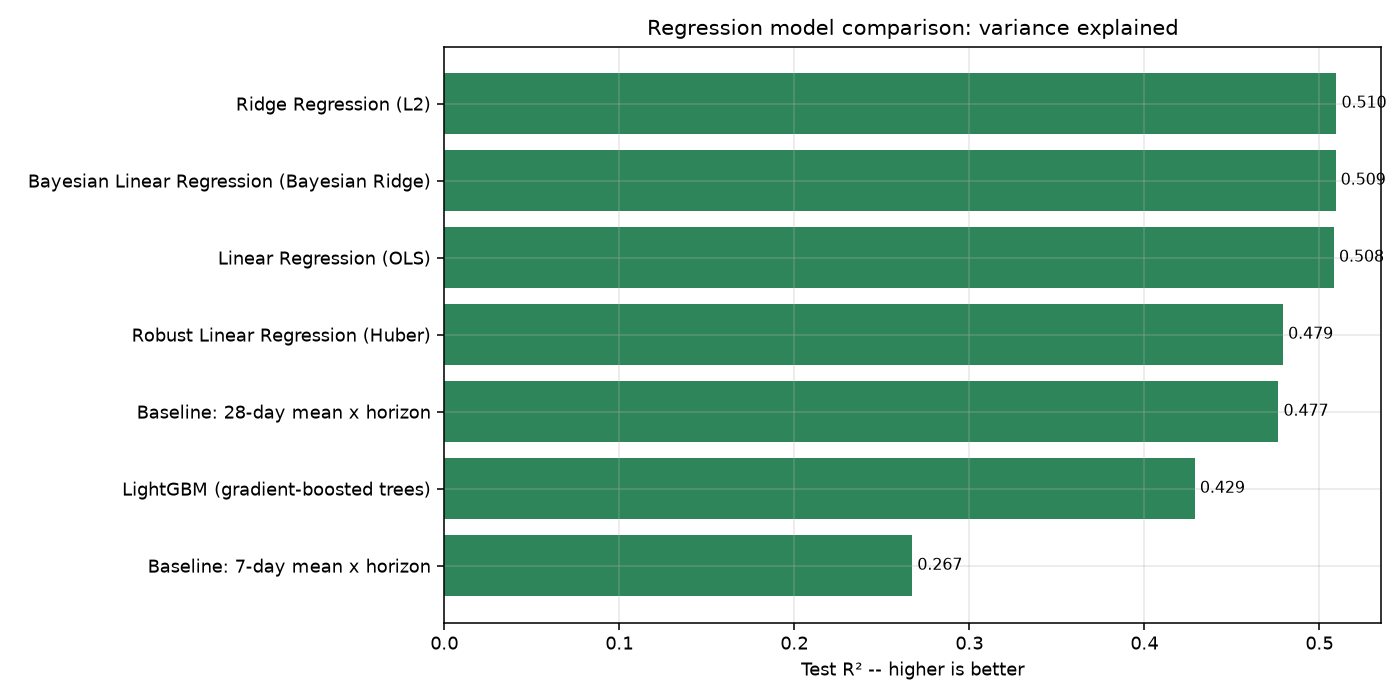

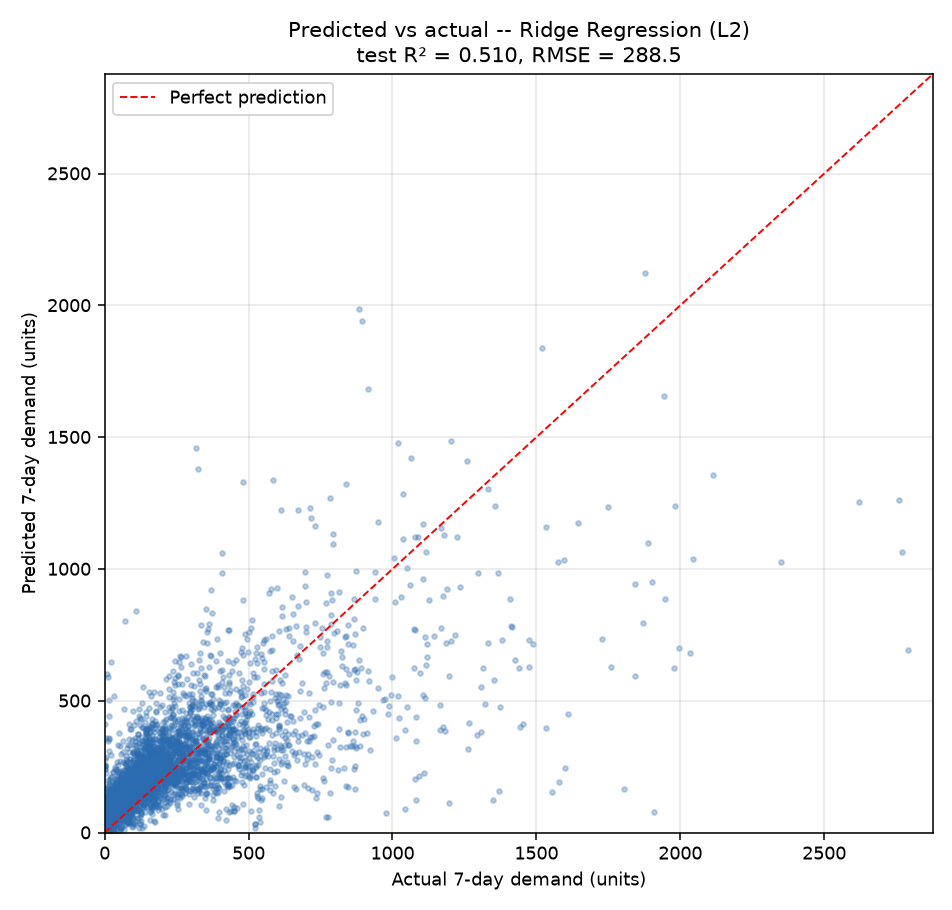

In [3]:
from IPython.display import Image, display
display(Image(filename=str(FIGS / 'model_regression_rmse.png')))
display(Image(filename=str(FIGS / 'model_regression_r2.png')))
display(Image(filename=str(FIGS / 'model_predicted_vs_actual.png')))

## Syllabus mapping for each model

In [4]:
reg[['model', 'unit', 'concept']]

,model,unit,concept
0,Ridge Regression (L2),Unit 2,Ridge regression; MAP estimate under a Gaussia...
1,Bayesian Linear Regression (Bayesian Ridge),Unit 2,Bayesian linear regression; posterior over wei...
2,Linear Regression (OLS),Unit 1 + Unit 2,Linear regression / least squares; equals the ...
3,Robust Linear Regression (Huber),Unit 2,Robust linear regression
4,Baseline: 28-day mean x horizon,Baseline (no learning),Moving-average rule of thumb
5,LightGBM (gradient-boosted trees),Advanced (beyond syllabus),Non-linear ensemble; provides TreeSHAP explana...
6,Baseline: 7-day mean x horizon,Baseline (no learning),Moving-average rule of thumb


### Least squares and maximum likelihood are the same estimator

Assume `y = Xβ + ε` with `ε ~ N(0, σ²I)`. The log-likelihood is

    log L(β) = −n/2·log(2πσ²) − (1/2σ²)·‖y − Xβ‖²

Only the final term depends on β, so **maximising the likelihood is exactly minimising the sum of squared errors**. That is why the table has no separate 'MLE model': `LinearRegression` already is one.

### Ridge: the MAP estimate under a Gaussian prior

,alpha,MAE,MSE,RMSE,R2,RMSLE
0,0.01,110.0311,44579.0615,211.1375,0.4230,1.4214
1,0.10,110.0239,44574.7766,211.1274,0.4231,1.4212
2,1.00,109.9482,44531.6345,211.0252,0.4237,1.4204
3,10.00,109.8468,44472.2076,210.8843,0.4244,1.4201
4,100.00,109.6931,44395.8182,210.7032,0.4254,1.4189
5,1000.00,109.8049,44459.6108,210.8545,0.4246,1.4090


Selected alpha = 100.0 (chosen on VALIDATION, not on test)


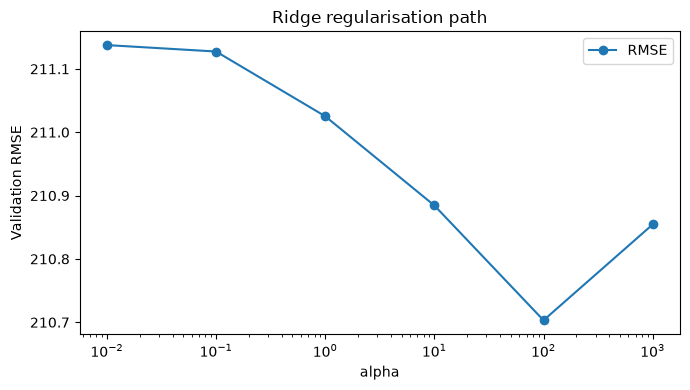

In [5]:
alpha = pd.read_csv(REPORTS / 'ridge_alpha_search.csv')
display(alpha.round(4))
best = alpha.loc[alpha['RMSE'].idxmin(), 'alpha']
print(f'Selected alpha = {best} (chosen on VALIDATION, not on test)')
ax = alpha.plot(x='alpha', y='RMSE', logx=True, marker='o', figsize=(7,4))
ax.set_ylabel('Validation RMSE'); ax.set_title('Ridge regularisation path')
plt.tight_layout(); plt.show()

Putting a prior `β ~ N(0, τ²I)` on the weights and taking the MAP estimate gives the ridge objective `‖y − Xβ‖² + λ‖β‖²` with `λ = σ²/τ²`. Ridge is therefore the Bayesian counterpart of OLS.

### Bayesian linear regression gives a distribution, not a point

In [6]:
import joblib
from xaierp.features.builder import load_features, regression_features, split_frames, xy
from xaierp.models.regression import predictive_std
feats = load_features(); te = split_frames(feats)['test']
rf = regression_features(feats)
X, y = xy(te, rf, 'future_7d_demand')
br = joblib.load(resolve(CFG['paths']['models']) / 'reg_bayesian_ridge.joblib')
mu = br.predict(X); sd = predictive_std(br, X)
print('Predictive std available:', sd is not None)
print(f'mean predictive std = {sd.mean():.2f} units')
k = np.argsort(-sd)[:5]
pd.DataFrame({'prediction': mu[k].round(1), 'predictive_std': sd[k].round(1),
              'actual': y[k].round(1)})

Predictive std available: True
mean predictive std = 281.06 units


,prediction,predictive_std,actual
0,3108.199951,294.600006,4362.0
1,3045.500000,294.399994,4771.0
2,2860.600098,289.600006,4092.0
3,3136.800049,289.000000,4559.0
4,2352.600098,288.299988,3410.0


### Robust regression: why Huber is in the table

In [7]:
d = pd.read_parquet(resolve(CFG['paths']['processed']) / 'daily_demand_panel.parquet')['demand']
print(f'max single SKU-day demand : {d.max():,.0f} units')
print(f'99th percentile           : {d.quantile(0.99):,.0f} units')
print(f'skewness                  : {d.skew():.1f}')
print('\nSquared error weights that 9,480-unit day ~ (9480/69)^2 ≈ '
      f'{(d.max()/d.quantile(0.90))**2:,.0f}x a typical day.')

max single SKU-day demand : 9,480 units
99th percentile           : 326 units
skewness                  : 24.6

Squared error weights that 9,480-unit day ~ (9480/69)^2 ≈ 18,876x a typical day.


## What actually won, and the honest surprise

In [8]:
s = json.loads((REPORTS / 'model_summary.json').read_text())
print('Best:', s['best_regression_model'])
print(f"  test RMSE {s['best_regression_test_RMSE']:.2f}")
print(f"  test MAE  {s['best_regression_test_MAE']:.2f}")
print(f"  test R2   {s['best_regression_test_R2']:.4f}")
print()
lg = reg.loc[reg['key'] == 'lightgbm'].iloc[0]
rd = reg.loc[reg['key'] == 'ridge_regression'].iloc[0]
print(f"LightGBM test RMSE {lg['test_RMSE']:.2f} vs Ridge {rd['test_RMSE']:.2f}")
print('The gradient-boosted model LOSES to a regularised linear model here.')

Best: Ridge Regression (L2)
  test RMSE 288.53
  test MAE  136.36
  test R2   0.5097

LightGBM test RMSE 311.43 vs Ridge 288.53
The gradient-boosted model LOSES to a regularised linear model here.


That result is reported as found, not hidden. The reasoning is in [`docs/model_selection.md`](../docs/model_selection.md).